# LAB 09 — Bias, Variance and Imbalanced Data  
## Student Information   
Name: Saba Mahar    
Student ID: 023-24-0141    
Section: H    
GitHub:    
Kaggle:    
Dataset: Stroke Prediction Dataset (Kaggle)    
Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset      

## Part 0 — Setup and the Data

In [15]:
#Part0

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEED = 42

df = pd.read_csv("hMxGyb.csv")

print("Shape:", df.shape)
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nGender value counts:")
print(df["gender"].value_counts())
print("\nStroke counts:")
print(df["stroke"].value_counts())
print("\nStroke percentages:")
print(df["stroke"].value_counts(normalize=True) * 100)

Shape: (5110, 12)
Missing values per column:
bmi    201
dtype: int64

Gender value counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke percentages:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [16]:
df = df[df["gender"] != "Other"].copy()
df = df.drop(columns=["id"])

y = df["stroke"]
X = pd.get_dummies(df.drop(columns=["stroke"]), drop_first=True)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5109, 15)
y shape: (5109,)


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

bmi_median = X_train["bmi"].median()
X_train["bmi"] = X_train["bmi"].fillna(bmi_median)
X_test["bmi"] = X_test["bmi"].fillna(bmi_median)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("Train strokes:", y_train.sum(), "Test strokes:", y_test.sum())

X_train: (4087, 15) X_test: (1022, 15)
Train strokes: 199 Test strokes: 50


**Answer (a):**
The data is very imbalanced, 4.9% of patients had a stroke. We used `stratify=y` so that this same 4.9% ratio is kept in both the train and test sets. With only about 50 stroke cases in the whole test set, a few unlucky or lucky predictions can swing the recall and precision numbers by a lot, so the test metrics become noisier than they'd be with a bigger minority class.

## Part 1 — The Accuracy Trap

In [18]:
#Part1

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, ConfusionMatrixDisplay

dummy = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Dummy baseline accuracy:", round(accuracy_score(y_test, dummy_pred), 4))

Dummy baseline accuracy: 0.9511


,Metric,Logistic Regression
0,Accuracy,0.952055
1,Precision,1.000000
2,Recall,0.020000
3,F1-Score,0.039216
4,ROC AUC,0.839424
5,PR AUC,0.269219


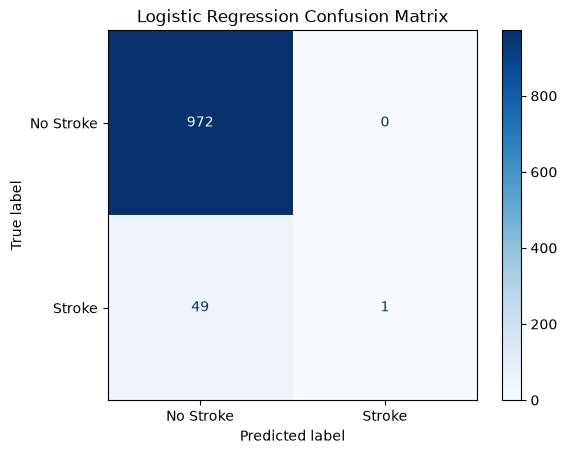

In [19]:
def get_metrics(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1-Score": f1_score(y_te, pred),
        "ROC AUC": roc_auc_score(y_te, proba),
        "PR AUC": average_precision_score(y_te, proba)
    }

lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr_metrics = get_metrics(lr, X_train_s, y_train, X_test_s, y_test)

lr_results = pd.DataFrame({"Metric": list(lr_metrics.keys()), "Logistic Regression": list(lr_metrics.values())})
display(lr_results)

ConfusionMatrixDisplay.from_estimator(lr, X_test_s, y_test, display_labels=["No Stroke", "Stroke"], cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

**Answer (a):**
The dummy baseline predicts "no stroke," gets 95.1% accuracy. Logistic Regression gets 95.2% accuracy barely better even though it's an actual trained model. This proves accuracy is useless.

**Answer (b):**
The confusion matrix shows Logistic Regression catches only 1 out of 50 stroke cases at the default threshold, meaning 49 false negatives. A false negative here means a patient who actually have a stroke gets told they are low-risk, which could be dangerous. Instead of accuracy, we should trust recall.

## Part 2 — Underfitting, Overfitting, Bias and Variance

### Task 2.1 — Validation Curve

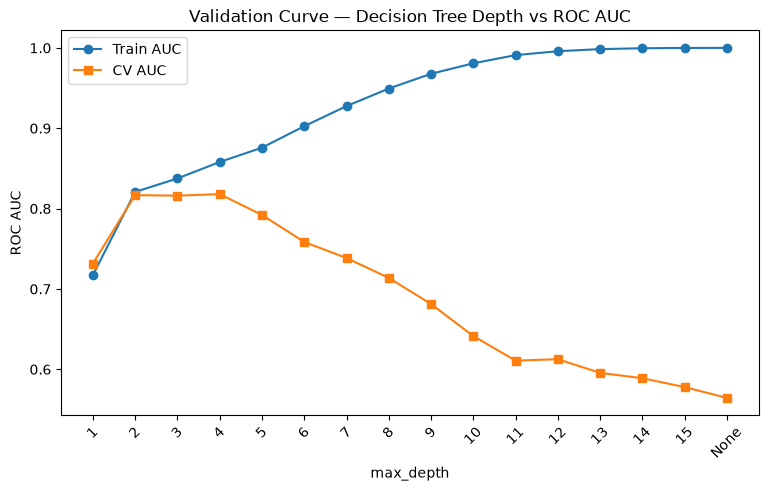

Best depth by CV AUC: 4 -> CV AUC: 0.818


In [20]:
#Task2.1

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train_aucs = []
cv_aucs = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tree.fit(X_train, y_train)
    train_auc = roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1])
    cv_auc = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    train_aucs.append(train_auc)
    cv_aucs.append(cv_auc)

depth_labels = [str(d) for d in depths]

plt.figure(figsize=(9, 5))
plt.plot(depth_labels, train_aucs, marker="o", label="Train AUC")
plt.plot(depth_labels, cv_aucs, marker="s", label="CV AUC")
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve — Decision Tree Depth vs ROC AUC")
plt.legend()
plt.xticks(rotation=45)
plt.show()

best_depth = depths[int(np.argmax(cv_aucs))]
print("Best depth by CV AUC:", best_depth, "-> CV AUC:", round(max(cv_aucs), 4))

### Task 2.2 — Learning Curves

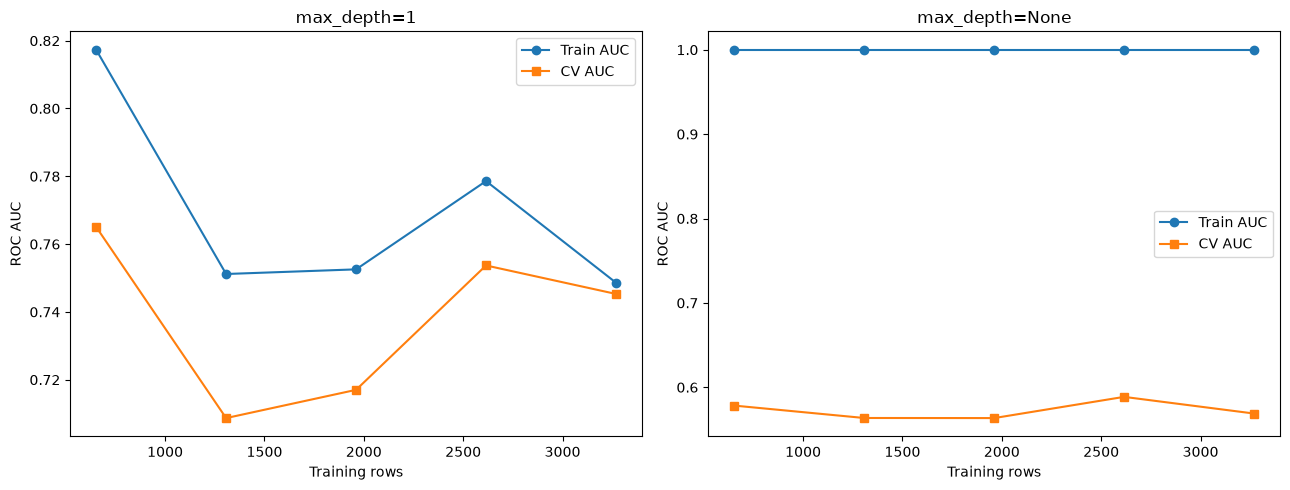

In [21]:
#Task2.2

from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, d, title in zip(axes, [1, None], ["max_depth=1", "max_depth=None"]):
    sizes, train_scores, valid_scores = learning_curve(
        DecisionTreeClassifier(max_depth=d, random_state=SEED),
        X_train, y_train, cv=5, scoring="roc_auc",
        train_sizes=np.linspace(0.2, 1.0, 5), random_state=SEED
    )
    ax.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train AUC")
    ax.plot(sizes, valid_scores.mean(axis=1), marker="s", label="CV AUC")
    ax.set_xlabel("Training rows")
    ax.set_ylabel("ROC AUC")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

### Task 2.3 — Measuring Variance Directly

In [22]:
#Task2.3

rng = np.random.default_rng(SEED)
n_boot = 40

variance_rows = []

for d in [1, 3, None]:
    probs = np.zeros((n_boot, len(X_test)))
    single_aucs = []
    for b in range(n_boot):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        Xb = X_train.iloc[idx]
        yb = y_train.iloc[idx]
        tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        tree.fit(Xb, yb)
        p = tree.predict_proba(X_test)[:, 1]
        probs[b] = p
        single_aucs.append(roc_auc_score(y_test, p))

    mean_variance = probs.var(axis=0).mean()
    mean_single_auc = np.mean(single_aucs)
    averaged_auc = roc_auc_score(y_test, probs.mean(axis=0))

    variance_rows.append({
        "max_depth": d,
        "Mean Prediction Variance": mean_variance,
        "Mean Single-Tree AUC": mean_single_auc,
        "Averaged-Prediction AUC": averaged_auc
    })

variance_table = pd.DataFrame(variance_rows)
variance_table

,max_depth,Mean Prediction Variance,Mean Single-Tree AUC,Averaged-Prediction AUC
0,1.0,0.000680,0.762342,0.813169
1,3.0,0.001668,0.796440,0.834290
2,NaN,0.041972,0.555248,0.756595


**Answer (a):**
From the validation curve, depth 1 and 2 underfit. Past depth 5 or so, the tree starts overfitting. The best depth by CV AUC is depth 4 (CV AUC 0.818), which is the sweet spot between these two zones.

**Answer (b):**
High bias shows up as both train and CV scores being low and close together. High variance shows up as a big gap between train and CV scores. More data can help narrow the gap a bit, but it won't fully fix it since the real problem is the model memorizing instead of generalizing.

**Answer (c):**
Variance goes up sharply with depth. Averaging the 40 bootstrap trees predictions always beats a single tree's average AUC — for depth=None. In Lab 4: it trains many high-variance trees on bootstrapped data and averages their predictions, which cancels out a lot of the individual trees' noise.

**Answer (d):**
The bias-variance trade-off is the balance between a model being too simple (bad at everything) and too complex (great on training data but unstable and bad at generalizing). Depth 1 sits in the high-bias zone, depth None sits in the high-variance zone, and depth 3 is a middle.

## Part 3 — ROC, AUC, Precision-Recall and Thresholds

### Task 3.1 — Compare Models with Curves

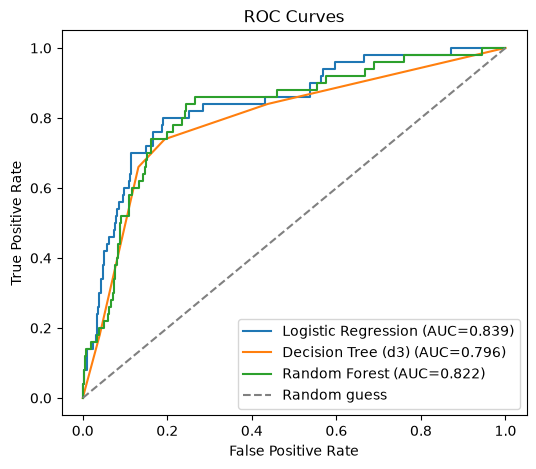

In [23]:
#Task3.1

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, precision_recall_curve

lr_model = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_s, y_train)
dt_model = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
rf_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED).fit(X_train, y_train)

lr_proba = lr_model.predict_proba(X_test_s)[:, 1]
dt_proba = dt_model.predict_proba(X_test)[:, 1]
rf_proba = rf_model.predict_proba(X_test)[:, 1]

plt.figure(figsize=(6, 5))
for name, proba in [("Logistic Regression", lr_proba), ("Decision Tree (d3)", dt_proba), ("Random Forest", rf_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

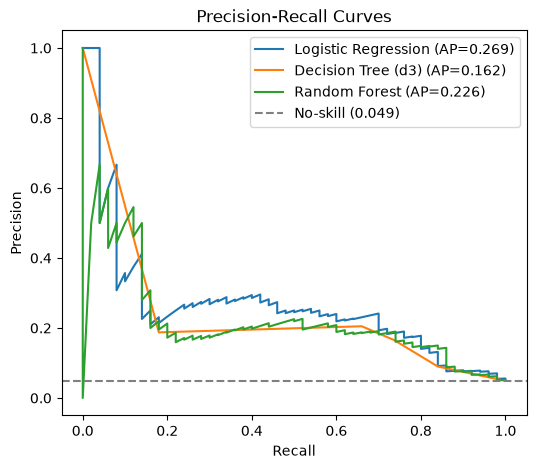

In [24]:
no_skill = y_test.mean()

plt.figure(figsize=(6, 5))
for name, proba in [("Logistic Regression", lr_proba), ("Decision Tree (d3)", dt_proba), ("Random Forest", rf_proba)]:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(rec, prec, label=f"{name} (AP={ap:.3f})")
plt.axhline(no_skill, linestyle="--", color="gray", label=f"No-skill ({no_skill:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

### Task 3.2 — Choose a Decision Threshold

In [25]:
#Task3.2

from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(LogisticRegression(max_iter=1000, random_state=SEED), X_train_s, y_train, cv=5, method="predict_proba")[:, 1]

thresholds = np.linspace(0.01, 0.99, 981)
chosen_threshold = 0

for t in sorted(thresholds, reverse=True):
    preds = (oof_proba >= t).astype(int)
    recall = ((preds == 1) & (y_train == 1)).sum() / (y_train == 1).sum()
    if recall >= 0.80:
        chosen_threshold = t
        break

print("Chosen threshold:", round(chosen_threshold, 3))

Chosen threshold: 0.048


In [26]:
from sklearn.metrics import confusion_matrix

test_pred_thr = (lr_proba >= chosen_threshold).astype(int)

print("Test recall:", round(recall_score(y_test, test_pred_thr), 4))
print("Test precision:", round(precision_score(y_test, test_pred_thr), 4))
print("Flagged patients:", test_pred_thr.sum())

cm = confusion_matrix(y_test, test_pred_thr)
tn, fp, fn, tp = cm.ravel()
print("False alarms (FP):", fp)
print("Missed strokes (FN):", fn)
print(cm)

Test recall: 0.82
Test precision: 0.1297
Flagged patients: 316
False alarms (FP): 275
Missed strokes (FN): 9
[[697 275]
 [  9  41]]


**Answer (a):**
Both can be true because ROC AUC measures how well the model ranks stroke patients above non-stroke patients across every possible threshold, not just at 0.5.

**Answer (b):**
The Precision-Recall curve is more informative because with such a rare positive class, ROC curves can look deceptively good. The no-skill line shows much more honestly how hard it actually is to get good precision while catching strokes.

**Answer (c):**
At the chosen threshold, recall on test jumps to 0.82 but precision drops to about 0.13, meaning 275 patients get flagged who don't actually have a stroke (false alarms). Whether that's acceptable depends on what a flag costs, if it just means "get a follow-up screening," catching 4 in 5 strokes for the price of some extra screenings seems worth it; if a flag means something more invasive or costly, 275 false alarms for every true stroke-positive patient might be too expensive to justify.

## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare the Methods

In [27]:
#Task4.1

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

def resample_metrics(method_name, model_name, X_tr, y_tr, X_te, model):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "Model": model_name, "Method": method_name,
        "Train Rows": len(y_tr), "Train Strokes": int(y_tr.sum()),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba),
        "PR AUC": average_precision_score(y_test, proba)
    }

ros = RandomOverSampler(random_state=SEED)
rus = RandomUnderSampler(random_state=SEED)
sm = SMOTE(random_state=SEED)

Xs_over, ys_over = ros.fit_resample(X_train_s, y_train)
X_over, y_over = ros.fit_resample(X_train, y_train)
Xs_under, ys_under = rus.fit_resample(X_train_s, y_train)
X_under, y_under = rus.fit_resample(X_train, y_train)
Xs_smote, ys_smote = sm.fit_resample(X_train_s, y_train)
X_smote, y_smote = sm.fit_resample(X_train, y_train)

combos = [
    ("No Resampling", X_train_s, y_train, X_train, y_train, None),
    ("class_weight=balanced", X_train_s, y_train, X_train, y_train, "balanced"),
    ("Random Undersample", Xs_under, ys_under, X_under, y_under, None),
    ("Random Oversample", Xs_over, ys_over, X_over, y_over, None),
    ("SMOTE", Xs_smote, ys_smote, X_smote, y_smote, None),
]

rows = []
for name, Xs, ys, Xr, yr, cw in combos:
    lr_r = LogisticRegression(max_iter=1000, random_state=SEED, class_weight=cw)
    rows.append(resample_metrics(name, "Logistic Regression", Xs, ys, X_test_s, lr_r))
    rf_r = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, class_weight=cw)
    rows.append(resample_metrics(name, "Random Forest", Xr, yr, X_test, rf_r))

resampling_table = pd.DataFrame(rows)
resampling_table

,Model,Method,Train Rows,Train Strokes,Precision,Recall,F1-Score,ROC AUC,PR AUC
0,Logistic Regression,No Resampling,4087,199,1.000000,0.02,0.039216,0.839424,0.269219
1,Random Forest,No Resampling,4087,199,0.000000,0.00,0.000000,0.822449,0.225524
2,Logistic Regression,class_weight=balanced,4087,199,0.134680,0.80,0.230548,0.839547,0.259548
3,Random Forest,class_weight=balanced,4087,199,0.189474,0.72,0.300000,0.815041,0.198692
4,Logistic Regression,Random Undersample,398,199,0.124620,0.82,0.216359,0.835206,0.233816
5,Random Forest,Random Undersample,398,199,0.105000,0.84,0.186667,0.820309,0.202954
6,Logistic Regression,Random Oversample,7776,3888,0.133333,0.80,0.228571,0.838457,0.264559
7,Random Forest,Random Oversample,7776,3888,0.188235,0.32,0.237037,0.811091,0.190593
8,Logistic Regression,SMOTE,7776,3888,0.133779,0.80,0.229226,0.840638,0.287624
9,Random Forest,SMOTE,7776,3888,0.162791,0.28,0.205882,0.781399,0.174997


### Task 4.2 — The Classic Mistake

In [28]:
#Task4.2

X_filled = X.copy()
X_filled["bmi"] = X_filled["bmi"].fillna(X_filled["bmi"].median())

sm_wrong = SMOTE(random_state=SEED)
X_res_wrong, y_res_wrong = sm_wrong.fit_resample(X_filled, y)
Xtr_w, Xte_w, ytr_w, yte_w = train_test_split(X_res_wrong, y_res_wrong, test_size=0.2, random_state=SEED, stratify=y_res_wrong)

rf_wrong = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
rf_wrong.fit(Xtr_w, ytr_w)
pred_wrong = rf_wrong.predict(Xte_w)
proba_wrong = rf_wrong.predict_proba(Xte_w)[:, 1]

correct_row = resampling_table[(resampling_table["Model"] == "Random Forest") & (resampling_table["Method"] == "SMOTE")].iloc[0]

leakage_table = pd.DataFrame({
    "Version": ["SMOTE before split (WRONG)", "SMOTE after split (CORRECT)"],
    "Precision": [precision_score(yte_w, pred_wrong), correct_row["Precision"]],
    "Recall": [recall_score(yte_w, pred_wrong), correct_row["Recall"]],
    "F1-Score": [f1_score(yte_w, pred_wrong), correct_row["F1-Score"]],
    "ROC AUC": [roc_auc_score(yte_w, proba_wrong), correct_row["ROC AUC"]],
    "PR AUC": [average_precision_score(yte_w, proba_wrong), correct_row["PR AUC"]]
})

leakage_table

,Version,Precision,Recall,F1-Score,ROC AUC,PR AUC
0,SMOTE before split (WRONG),0.928283,0.945473,0.936799,0.984767,0.985554
1,SMOTE after split (CORRECT),0.162791,0.280000,0.205882,0.781399,0.174997


**Answer (a):**
For Logistic Regression, recall jumped a lot once we moved away from "No Resampling", while ROC AUC barely moved. What changed is where the decision boundary sits relative to the default 0.5 cutoff, what stayed the same is the model's underlying ability to rank patients, which resampling doesn't really touch for a model like Logistic Regression.

**Answer (b):**
Random Forest did not react the same way its recall stayed much lower even after balancing. One likely reason is that Random Forest builds many trees on bootstrapped samples already unlike Logistic Regression's single global decision boundary.

**Answer (c):**
The wrong-order SMOTE result looks almost perfect compared to the correct order's much more modest numbers. This is because when SMOTE runs on the whole dataset before splitting so the model has effectively already "seen" very similar patients during training. Information has leaked from the test set into the training process.

**Answer (d):**
I'd pick `class_weight='balanced'` for this hospital. It gives basically the same recall boost as SMOTE or oversampling, needs no extra library or synthetic data, doesn't change the size or nature of the training set, and is the simplest one-line change to make.

## Part 5 — Noisy Data

### Task 5.1 — Label Noise

,Logistic Regression,Decision Tree (d3),Decision Tree (full),Random Forest
0.00,0.8394,0.7956,0.5797,0.8224
0.05,0.8241,0.8014,0.5529,0.8034
0.10,0.8052,0.7830,0.5119,0.7527
0.20,0.7743,0.7260,0.5045,0.6831


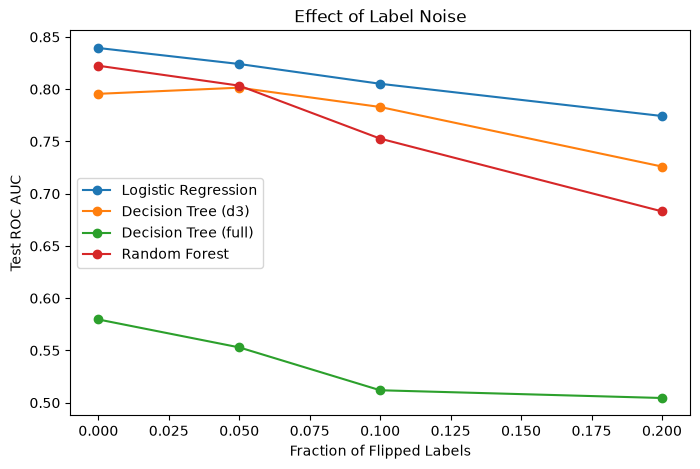

In [29]:
#Task5.1

def flip_labels(y, frac, rng):
    y = y.copy()
    n_flip = int(len(y) * frac)
    idx = rng.choice(len(y), n_flip, replace=False)
    y.iloc[idx] = 1 - y.iloc[idx].values
    return y

noise_models = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree (d3)": lambda: DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Decision Tree (full)": lambda: DecisionTreeClassifier(random_state=SEED),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
}

fractions = [0, 0.05, 0.10, 0.20]
label_results = {m: [] for m in noise_models}

for frac in fractions:
    reps = 1 if frac == 0 else 5
    scores = {m: [] for m in noise_models}
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        y_noisy = flip_labels(y_train, frac, rng)
        scaler_n = StandardScaler().fit(X_train)
        Xtr_s = scaler_n.transform(X_train)
        Xte_s = scaler_n.transform(X_test)
        for mname, mfn in noise_models.items():
            mdl = mfn()
            if mname == "Logistic Regression":
                mdl.fit(Xtr_s, y_noisy)
                proba = mdl.predict_proba(Xte_s)[:, 1]
            else:
                mdl.fit(X_train, y_noisy)
                proba = mdl.predict_proba(X_test)[:, 1]
            scores[mname].append(roc_auc_score(y_test, proba))
    for mname in noise_models:
        label_results[mname].append(np.mean(scores[mname]))

label_noise_table = pd.DataFrame(label_results, index=fractions)
display(label_noise_table.round(4))

plt.figure(figsize=(8, 5))
for col in label_noise_table.columns:
    plt.plot(label_noise_table.index, label_noise_table[col], marker="o", label=col)
plt.xlabel("Fraction of Flipped Labels")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Label Noise")
plt.legend()
plt.show()

### Task 5.2 — Feature Noise

,Logistic Regression,Decision Tree (d3),Decision Tree (full),Random Forest
0.0,0.8394,0.7956,0.5797,0.8224
0.5,0.8337,0.7995,0.5608,0.8140
1.0,0.8098,0.7610,0.5283,0.7870
2.0,0.7695,0.6942,0.5309,0.7406


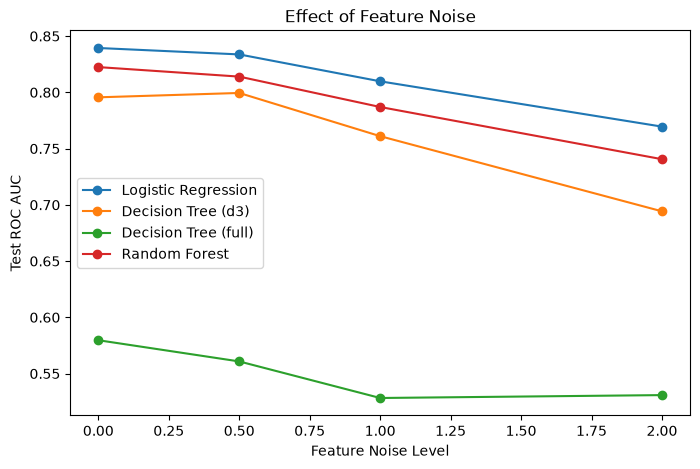

In [30]:
#Task5.2

noise_cols = ["age", "avg_glucose_level", "bmi"]
stds = X_train[noise_cols].std()
levels = [0, 0.5, 1, 2]
feature_results = {m: [] for m in noise_models}

for level in levels:
    reps = 1 if level == 0 else 5
    scores = {m: [] for m in noise_models}
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        Xn = X_train.copy()
        for c in noise_cols:
            Xn[c] = Xn[c] + rng.normal(0, 1, len(Xn)) * stds[c] * level
        scaler_n = StandardScaler().fit(Xn)
        Xn_s = scaler_n.transform(Xn)
        Xte_s = scaler_n.transform(X_test)
        for mname, mfn in noise_models.items():
            mdl = mfn()
            if mname == "Logistic Regression":
                mdl.fit(Xn_s, y_train)
                proba = mdl.predict_proba(Xte_s)[:, 1]
            else:
                mdl.fit(Xn, y_train)
                proba = mdl.predict_proba(X_test)[:, 1]
            scores[mname].append(roc_auc_score(y_test, proba))
    for mname in noise_models:
        feature_results[mname].append(np.mean(scores[mname]))

feature_noise_table = pd.DataFrame(feature_results, index=levels)
display(feature_noise_table.round(4))

plt.figure(figsize=(8, 5))
for col in feature_noise_table.columns:
    plt.plot(feature_noise_table.index, feature_noise_table[col], marker="o", label=col)
plt.xlabel("Feature Noise Level")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Feature Noise")
plt.legend()
plt.show()

### Task 5.3 — SMOTE and Noisy Labels

In [31]:
#Task5.3

smote_noise_rows = []

for r in range(3):
    rng = np.random.default_rng(SEED + r)
    y_noisy = flip_labels(y_train, 0.10, rng)

    scaler_n = StandardScaler().fit(X_train)
    Xtr_s = scaler_n.transform(X_train)
    Xte_s = scaler_n.transform(X_test)

    lr_ns = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr_s, y_noisy)
    proba = lr_ns.predict_proba(Xte_s)[:, 1]
    smote_noise_rows.append(("Logistic Regression", "No SMOTE", roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

    rf_ns = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED).fit(X_train, y_noisy)
    proba = rf_ns.predict_proba(X_test)[:, 1]
    smote_noise_rows.append(("Random Forest", "No SMOTE", roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

    sm_n = SMOTE(random_state=SEED)
    Xs_res, ys_res = sm_n.fit_resample(Xtr_s, y_noisy)
    lr_s = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xs_res, ys_res)
    proba = lr_s.predict_proba(Xte_s)[:, 1]
    smote_noise_rows.append(("Logistic Regression", "SMOTE", roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

    X_res, y_res = sm_n.fit_resample(X_train, y_noisy)
    rf_s = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED).fit(X_res, y_res)
    proba = rf_s.predict_proba(X_test)[:, 1]
    smote_noise_rows.append(("Random Forest", "SMOTE", roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

smote_noise_df = pd.DataFrame(smote_noise_rows, columns=["Model", "Method", "ROC AUC", "PR AUC"])
smote_noise_summary = smote_noise_df.groupby(["Model", "Method"])[["ROC AUC", "PR AUC"]].mean()
smote_noise_summary.round(4)

ROC AUC  PR AUC
Model               Method                   
Logistic Regression No SMOTE   0.8102  0.2242
                    SMOTE      0.8101  0.2306
Random Forest       No SMOTE   0.7508  0.1603
                    SMOTE      0.6144  0.0778

**Answer (a):**
The full-depth Decision Tree is damaged the most. Random Forest is the most stable relative to its starting point. This matches Part 2: high-variance models have no "safety margin" and break down fast, while averaging across many trees (Random Forest) and a simple linear model both resist noise better.

**Answer (b):**
Label noise hurts more at a comparable level. Label noise is more damaging because a flipped label directly teaches the model the wrong answer for that patient.

**Answer (c):**
SMOTE creates new minority points by interpolating between existing minority neighbors, it will implify the mistake instead of just leaving it as one bad data point.

## Part 6 — Final Decision and Conclusion

In [32]:
#Part6

chosen_pred = (lr_proba >= chosen_threshold).astype(int)
default_pred = (lr_proba >= 0.5).astype(int)

def summarize(pred, label):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        "Threshold": label,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "False Alarms (FP)": fp,
        "Missed Strokes (FN)": fn
    }

final_table = pd.DataFrame([summarize(default_pred, "Default (0.5)"), summarize(chosen_pred, f"Chosen ({chosen_threshold:.3f})")])
final_table

,Threshold,Precision,Recall,F1-Score,False Alarms (FP),Missed Strokes (FN)
0,Default (0.5),1.000000,0.02,0.039216,0,49
1,Chosen (0.048),0.129747,0.82,0.224044,275,9


**Executive Summary**

My final approach is Logistic Regression with a custom decision threshold of about 0.048. On the test set this threshold gives recall of 0.82 which means 41 of 50 strokes caught and precision of about 0.13, compared to the default 0.5 threshold's recall of just 0.02. The price for this is 275 false alarms versus 0 at the default threshold. I avoided leakage throughout by fitting the scaler, the bmi median imputer, and the threshold only on the training data, never touching the test set until final evaluation. The clearest limitation of this analysis is that the test set only has 50 stroke patients, so a handful of different predictions could meaningfully shift these numbers, and the 0.80 recall target for the threshold was my own choice, not something the hospital explicitly set.

**Final Reflection**

(a) What was the single most surprising result in this lab?

*Your answer:* The SMOTE-before-split leakage mistake was the most surprising.

(b) If you had one more hour, what would you try next?

*Your answer:* I would try nothing as this lab takes too much time to do as i have other subjects too to do.